In [11]:
import pandas as pd 
import numpy as np
import seaborn as sns
%matplotlib inline 

In [4]:
df=pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv')

In [5]:
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [6]:
columns=['engine_displacement','horsepower','vehicle_weight','model_year','fuel_efficiency_mpg']
new_df=df[columns]

In [9]:
new_df.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

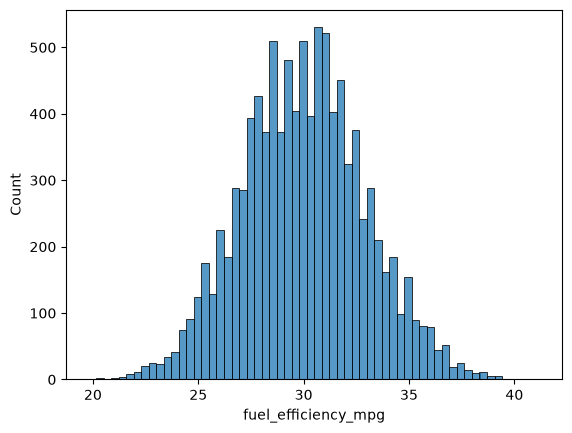

In [12]:
sns.histplot(new_df['fuel_efficiency_mpg'])

In [13]:
new_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   engine_displacement  10000 non-null  int64  
 1   horsepower           9123 non-null   float64
 2   vehicle_weight       10000 non-null  int64  
 3   model_year           10000 non-null  int64  
 4   fuel_efficiency_mpg  10000 non-null  float64
dtypes: float64(2), int64(3)
memory usage: 390.8 KB


In [14]:
new_df.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

In [15]:
new_df.describe()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
count,10000.000000,9123.000000,10000.000000,10000.000000,10000.000000
mean,2268.807000,254.446016,4286.754000,1999.549500,29.997700
std,183.447355,22.844613,266.212491,14.207925,2.930245
min,1590.000000,171.000000,3320.000000,1975.000000,19.800000
25%,2150.000000,239.000000,4110.000000,1987.000000,28.000000
50%,2270.000000,254.000000,4280.000000,2000.000000,30.000000
75%,2390.000000,270.000000,4470.000000,2012.000000,31.900000
max,3110.000000,334.000000,5460.000000,2024.000000,41.200000


In [16]:
n = len(new_df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = new_df.iloc[idx[:n_train]]
df_val = new_df.iloc[idx[n_train:n_train + n_val]]
df_test = new_df.iloc[idx[n_train + n_val:]]

In [17]:
y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [18]:
def prepare_X_zero(df):
    df_num = df.fillna(0)
    X = df_num.values
    return X

In [19]:
def prepare_X_mean(df):
    df_num = df.fillna(df.mean(numeric_only=True))
    X = df_num.values
    return X

In [22]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)
    
    return w[0], w[1:]

In [39]:
def rmse(y, y_pred):
    error = y_pred - y
    mse = (error ** 2).mean()
    return np.sqrt(mse)

In [20]:
X_train_zero = prepare_X_zero(df_train)
X_train_mean = prepare_X_mean(df_train)

In [21]:
X_val_zero = prepare_X_zero(df_val)
X_val_mean = prepare_X_mean(df_val)

In [24]:
w_0_zero, w_zero = train_linear_regression(X_train_zero, y_train)
w_0_mean, w_mean = train_linear_regression(X_train_mean, y_train)

In [25]:
y_pred_zero = w_0_zero + X_val_zero.dot(w_zero)
y_pred_mean = w_0_mean + X_val_mean.dot(w_mean)

In [32]:
rmse_zero=round(rmse(y_val, y_pred_zero),3)
rmse_zero

np.float64(2.205)

In [30]:
rmse_mean=round(rmse(y_val, y_pred_mean),3)
rmse_mean

np.float64(2.202)

In [33]:
def train_linear_regression_reg(X, y, r=0.0):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    reg = r * np.eye(XTX.shape[0])
    XTX = XTX + reg

    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)
    
    return w[0], w[1:]

In [34]:
for r in [0, 0.01, 0.1, 1,5, 10,100]:
    w_0, w = train_linear_regression_reg(X_train_zero, y_train, r=r)
    y_pred = w_0 + X_val_zero.dot(w)
    print(r,'rmse value=', round(rmse(y_val, y_pred),4))

0 rmse value= 2.2053
0.01 rmse value= 2.2058
0.1 rmse value= 2.2241
1 rmse value= 2.3492
5 rmse value= 2.4094
10 rmse value= 2.4195
100 rmse value= 2.4292


In [60]:
rmse_scores=[]

In [61]:
for s in [0,1, 2, 3,4,5,6,7,8,9]:
    df=new_df.copy()
    np.random.seed(s)
    idx = np.arange(n)
    np.random.shuffle(idx)
    
    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train:n_train + n_val]]
    df_test = df.iloc[idx[n_train + n_val:]]

    y_train = df_train.fuel_efficiency_mpg.values
    y_val = df_val.fuel_efficiency_mpg.values
    
    del df_train['fuel_efficiency_mpg']
    del df_val['fuel_efficiency_mpg']

    X_train_zero = prepare_X_zero(df_train)
    X_val_zero = prepare_X_zero(df_val)

    w_0, w = train_linear_regression(X_train_zero, y_train)

    
    y_pred = w_0 + X_val_zero.dot(w)
    rmse_val = rmse(y_val, y_pred)
    rmse_scores.append(rmse_val)

scores_std= round(np.std(rmse_scores),3)
scores_std


np.float64(0.029)

In [57]:
np.random.seed(9)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = new_df.iloc[idx[:n_train]]
df_val = new_df.iloc[idx[n_train:n_train + n_val]]
df_test = new_df.iloc[idx[n_train + n_val:]]

df_train_full = pd.concat([df_train, df_val], ignore_index=True)

y_train_full = df_train_full.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

del df_train_full['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

X_train_full = prepare_X_zero(df_train_full)
X_test = prepare_X_zero(df_test)

w_0, w = train_linear_regression_reg(X_train_full, y_train_full, r=0.001)

y_pred = w_0 + X_test.dot(w)

rmse_test=round(rmse(y_test, y_pred),3)
rmse_test

np.float64(2.236)